<a href="https://colab.research.google.com/github/Swathi-Chippa/FSD_LAB_306/blob/main/Dl20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


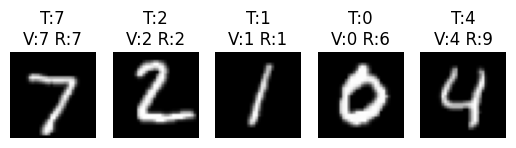

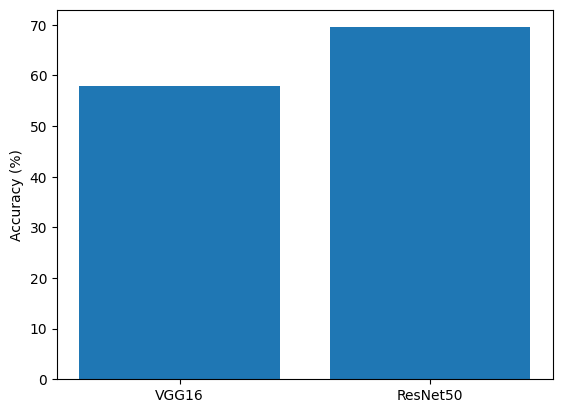

VGG16: 58.0 %
ResNet50: 69.5 %


In [ ]:


import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras import layers, Sequential

(x, y), (xt, yt) = tf.keras.datasets.mnist.load_data()
x, y = x[:1000], y[:1000]
xt, yt = xt[:200], yt[:200]

x = tf.image.resize(x[..., None], (32, 32))
xt = tf.image.resize(xt[..., None], (32, 32))
x = tf.repeat(x, 3, axis=-1)
xt = tf.repeat(xt, 3, axis=-1)

acc = []
pred = []

for net in [VGG16, ResNet50]:
    base = net(weights="imagenet", include_top=False, input_shape=(32,32,3))
    base.trainable = False

    model = Sequential([
        base,
        layers.Flatten(),
        layers.Dense(10, activation="softmax")
    ])

    model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(x, y, epochs=2, verbose=0)

    acc.append(model.evaluate(xt, yt, verbose=0)[1] * 100)
    pred.append(model.predict(xt[:5], verbose=0).argmax(axis=1))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(xt[i, :, :, 0], cmap="gray")
    plt.title(f"T:{yt[i]}\nV:{pred[0][i]} R:{pred[1][i]}")
    plt.axis("off")
plt.show()

plt.bar(["VGG16", "ResNet50"], acc)
plt.ylabel("Accuracy (%)")
plt.show()

print("VGG16:", round(acc[0], 2), "%")
print("ResNet50:", round(acc[1], 2), "%")

In [ ]:
!pip install -q -U datasets huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (9 outputs left out)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-a -> Negative
Worth the entertainment value of a rental, especially if you like action movies. This one features t -> Positive
its a totally average film with a few semi-alright action sequences that make the plot seem a little -> Negative
STAR RATING: ***** Saturday Night **** Friday Night *** Friday Morning ** Sunday Night * Monday Morn -> Negative
First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will n -> Positive
Accuracy: 85.5 %


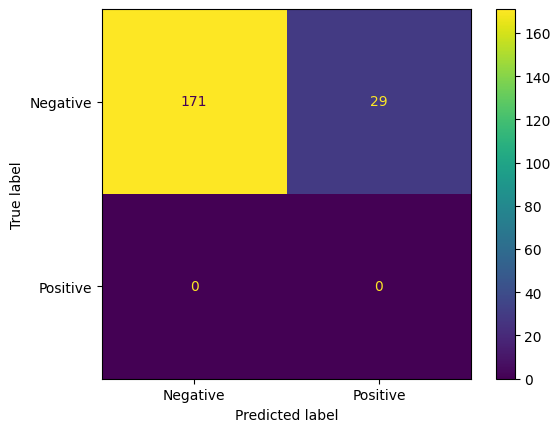

In [ ]:

!pip -q install transformers scikit-learn

from datasets import load_dataset
from transformers import pipeline
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Load IMDb dataset
data = load_dataset("stanfordnlp/imdb", split="test[:200]")

reviews = data["text"]
actual = data["label"]

print("Total reviews:", len(reviews))

# Load DistilBERT model
m = pipeline("sentiment-analysis",
             model="distilbert/distilbert-base-uncased-finetuned-sst-2-english")

# Predict sentiment
pred = []
for r in reviews:
    p = m(r[:512])[0]["label"]
    pred.append(1 if p == "POSITIVE" else 0)

# Display results
for r, p in zip(reviews[:5], pred[:5]):
    print(r[:100], "->", ["Negative", "Positive"][p])

# Accuracy
print("Accuracy:", round(accuracy_score(actual, pred)*100, 2), "%")

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    actual, pred, display_labels=["Negative", "Positive"])
plt.show()

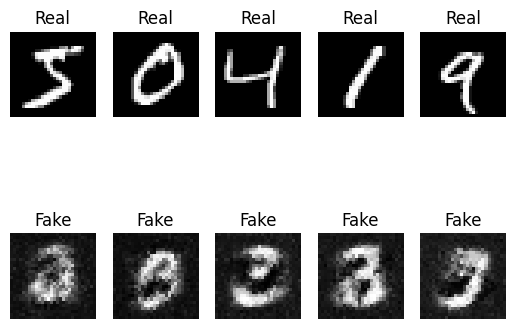

In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential
from tensorflow.keras.layers import *

# Generator
G = Sequential([
    Input((100,)),
    Dense(784, activation="tanh"),
    Reshape((28,28,1))
])

# Discriminator
D = Sequential([
    Input((28,28,1)),
    Flatten(),
    Dense(256),
    LeakyReLU(negative_slope=0.2),
    Dense(1, activation="sigmoid")
])

# Compile models
D.compile(optimizer="adam", loss="binary_crossentropy")
G.compile(optimizer="adam", loss="mse")

# Load MNIST dataset
(x,_),_ = tf.keras.datasets.mnist.load_data()
x = x[:500,...,None].astype("float32") / 127.5 - 1

# Train GAN
for i in range(3000):
    z = tf.random.normal((32,100))
    real = x[tf.random.uniform((32,), 0, 500, dtype=tf.int32)]

    # Train Discriminator
    D.train_on_batch(real, tf.ones((32,1)))
    D.train_on_batch(G(z), tf.zeros((32,1)))

    # Train Generator
    with tf.GradientTape() as tape:
        fake = G(z)
        loss = tf.keras.losses.binary_crossentropy(
            tf.ones((32,1)), D(fake))

    grads = tape.gradient(loss, G.trainable_variables)
    G.optimizer.apply_gradients(zip(grads, G.trainable_variables))

# Generate images
imgs = tf.concat([x[:5], G(tf.random.normal((5,100)))], axis=0)

# Display images
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(imgs[i,:,:,0], cmap="gray")
    plt.title("Real" if i<5 else "Fake")
    plt.axis("off")

plt.show()

In [ ]:
# 1. Install packages
!pip install -q huggingface_hub

import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 2. Automatically download dataset
file = hf_hub_download(
    repo_id="HackHedron/English_Telugu_Parallel_Corpus",
    filename="English-Telugu Parallel Corpus Dataset.csv",
    repo_type="dataset"
)

# 3. Load dataset
df = pd.read_csv(file).dropna()

print(df.head())
print(df.columns)

# 4. Select columns
ec = next(c for c in df.columns if 'eng' in c.lower())
tc = next(c for c in df.columns if 'tel' in c.lower())

# 5. Clean data
df[ec] = df[ec].astype(str).str.lower().str.strip()
df[tc] = df[tc].astype(str).str.strip()

df = df[df[ec].str.split().str.len().between(2,4)]
df = df.drop_duplicates(ec).head(150)

# 6. Prepare sentences
eng = df[ec].tolist()
tel = ['<start> '+s+' <end>' for s in df[tc]]

# 7. Tokenization
et = Tokenizer(filters='', oov_token='<unk>')
tt = Tokenizer(filters='', oov_token='<unk>')

et.fit_on_texts(eng)
tt.fit_on_texts(tel)

# 8. Padding
x = pad_sequences(et.texts_to_sequences(eng), padding='post')
y = pad_sequences(tt.texts_to_sequences(tel), padding='post')

D, T = y[:,:-1], y[:,1:]

# 9. Encoder
ei = Input(shape=(x.shape[1],))
e2 = Embedding(len(et.word_index)+1,256)(ei)

eo,h,c = LSTM(256,return_sequences=True,
              return_state=True)(e2)

# 10. Decoder
di = Input(shape=(D.shape[1],))
d2 = Embedding(len(tt.word_index)+1,256)(di)

do,_,_ = LSTM(256,return_sequences=True,
              return_state=True)(d2,initial_state=[h,c])

# 11. Attention
a = AdditiveAttention()([do,eo])

out = Dense(len(tt.word_index)+1,activation='softmax')(
    Concatenate()([do,a]))

# 12. Build model
model = Model([ei,di],out)

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# 13. Train model
history = model.fit([x,D],T,epochs=40,batch_size=8)


# 16. Display accuracy
print("Accuracy:",history.history['accuracy'][-1]*100)

# 18. Display dataset sentences
for i in range(5):
    print("\nEnglish:",eng[i])
    print("Telugu:",df[tc].iloc[i])

English-Telugu Parallel Corpus Dataset.c(…): reconstructing file:   0%|          |  0.00B /  124MB            

English-Telugu Parallel Corpus Dataset.c(…): downloading bytes:           |  0.00B            

                                             english  \
0                Tom started his car and drove away.   
1                  I think Tom understands all that.   
2                          I'll go tomorrow morning.   
3                            Which do you recommend?   
4  In order to generate an accurate weather forec...   

                                              telugu  
0       టామ్ తన కారును స్టార్ట్ చేసి దూరంగా నడిపాడు.  
1  టామ్ అంతా అర్థం చేసుకున్నాడని నేను అనుకుంటున్న...  
2                           నేను రేపు ఉదయం వెళ్తాను.  
3                     మీరు దేనిని సిఫార్సు చేస్తారు?  
4  రాబోయే 24 గంటల్లో ఖచ్చితమైన వాతావరణ సూచనను రూప...  
Index(['english', 'telugu'], dtype='object')


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 4, 256)    │     92,416 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 6, 256)    │     91,136 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 4, 256),  │    525,312 │ embedding[0][0]   │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 6, 256),  │    525,312 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ lstm[0][1],       │
│                     │ (None, 256)]      │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ additive_attention  │ (None, 6, 256)    │        256 │ lstm_1[0][0],     │
│ (AdditiveAttention) │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 6, 512)    │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ additive_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 6, 356)    │    182,628 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,417,060 (5.41 MB)

 Trainable params: 1,417,060 (5.41 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.3067 - loss: 5.1351
Epoch 2/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3689 - loss: 3.5224
Epoch 3/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4411 - loss: 3.2381
Epoch 4/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4900 - loss: 3.0932
Epoch 5/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5022 - loss: 2.9870
Epoch 6/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5022 - loss: 2.8653
Epoch 7/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5100 - loss: 2.7461
Epoch 8/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5278 - loss: 2.6002
Epoch 9/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5400 - loss: 2.4114
Epoch 10/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5500 - loss: 2.2037
Epoch 11/40
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6458 - loss: 1.7403